# Step 4b - Tealight masks, AI annotator (Gemini) and annotation



In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, random, shutil, re, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from sklearn.metrics import cohen_kappa_score

BASE = "/content/drive/MyDrive/COMP8240_PatchCore"
OUT = f"{BASE}/tealights_mvtec/tealight"        # MVTec layout
ANN = f"{BASE}/tealights_mvtec"                  # annotation files

def coco_masks(path, size=512):
    # polygons from a makesense COCO export
    c = json.load(open(path)); ps = {}
    for a in c["annotations"]:
        ps.setdefault(a["image_id"], []).extend(a["segmentation"])
    out = {}
    for im in c["images"]:
        name = os.path.splitext(os.path.basename(im["file_name"]))[0]
        m = Image.new("L", (im["width"], im["height"]), 0); dr = ImageDraw.Draw(m)
        for p in ps.get(im["id"], []):
            dr.polygon(list(zip(p[0::2], p[1::2])), fill=255)
        out[name] = np.array(m.resize((size, size), Image.NEAREST)) > 0
    return out

def compare(a, b):
    # agreement between two boolean masks of the same image
    inter, union, total = (a & b).sum(), (a | b).sum(), a.sum() + b.sum()
    return {"iou": inter / union if union else 1.0,
            "dice": 2 * inter / total if total else 1.0,
            "pixel_kappa": cohen_kappa_score(a.ravel(), b.ravel())}   # every pixel = one item

def split_answers(text):
    parts = re.split(r"^###\s*(\S+)\s*$", text, flags=re.M)
    return {parts[i].strip(): parts[i + 1].strip() for i in range(1, len(parts) - 1, 2)}

Mounted at /content/drive


# Part 1: My masks


In [2]:
human = coco_masks(f"{ANN}/annotations_coco.json")

for d in ["used", "empty"]:
    shutil.rmtree(f"{OUT}/ground_truth/{d}", ignore_errors=True)
    os.makedirs(f"{OUT}/ground_truth/{d}")

rows = []
for name, m in sorted(human.items()):
    d = name.split("_")[0]
    Image.fromarray((m * 255).astype(np.uint8)).save(f"{OUT}/ground_truth/{d}/{name}_mask.png")
    rows.append({"name": name, "type": d, "defect_area_pct": round(100 * m.mean(), 1)})
masks = pd.DataFrame(rows)

for d in ["used", "empty"]:
    imgs = sorted(f[:-4] for f in os.listdir(f"{OUT}/test/{d}") if f.endswith(".png"))
    msks = sorted(f[:-9] for f in os.listdir(f"{OUT}/ground_truth/{d}") if f.endswith("_mask.png"))
    print(f"{d}: {len(imgs)} images, {len(msks)} masks, pairs match: {imgs == msks}")
print(masks.groupby("type")["defect_area_pct"].describe().round(1))
print("empty masks:", masks.loc[masks.defect_area_pct == 0, "name"].tolist())
masks.to_csv(f"{ANN}/mask_summary.csv", index=False)

used: 49 images, 49 masks, pairs match: True
empty: 46 images, 46 masks, pairs match: True
       count  mean   std   min   25%   50%   75%   max
type                                                  
empty   46.0  40.0   5.2  30.0  36.7  39.3  43.6  56.6
used    49.0  14.8  14.4   2.3   4.5   7.6  21.5  53.7
empty masks: []


### Look at every mask


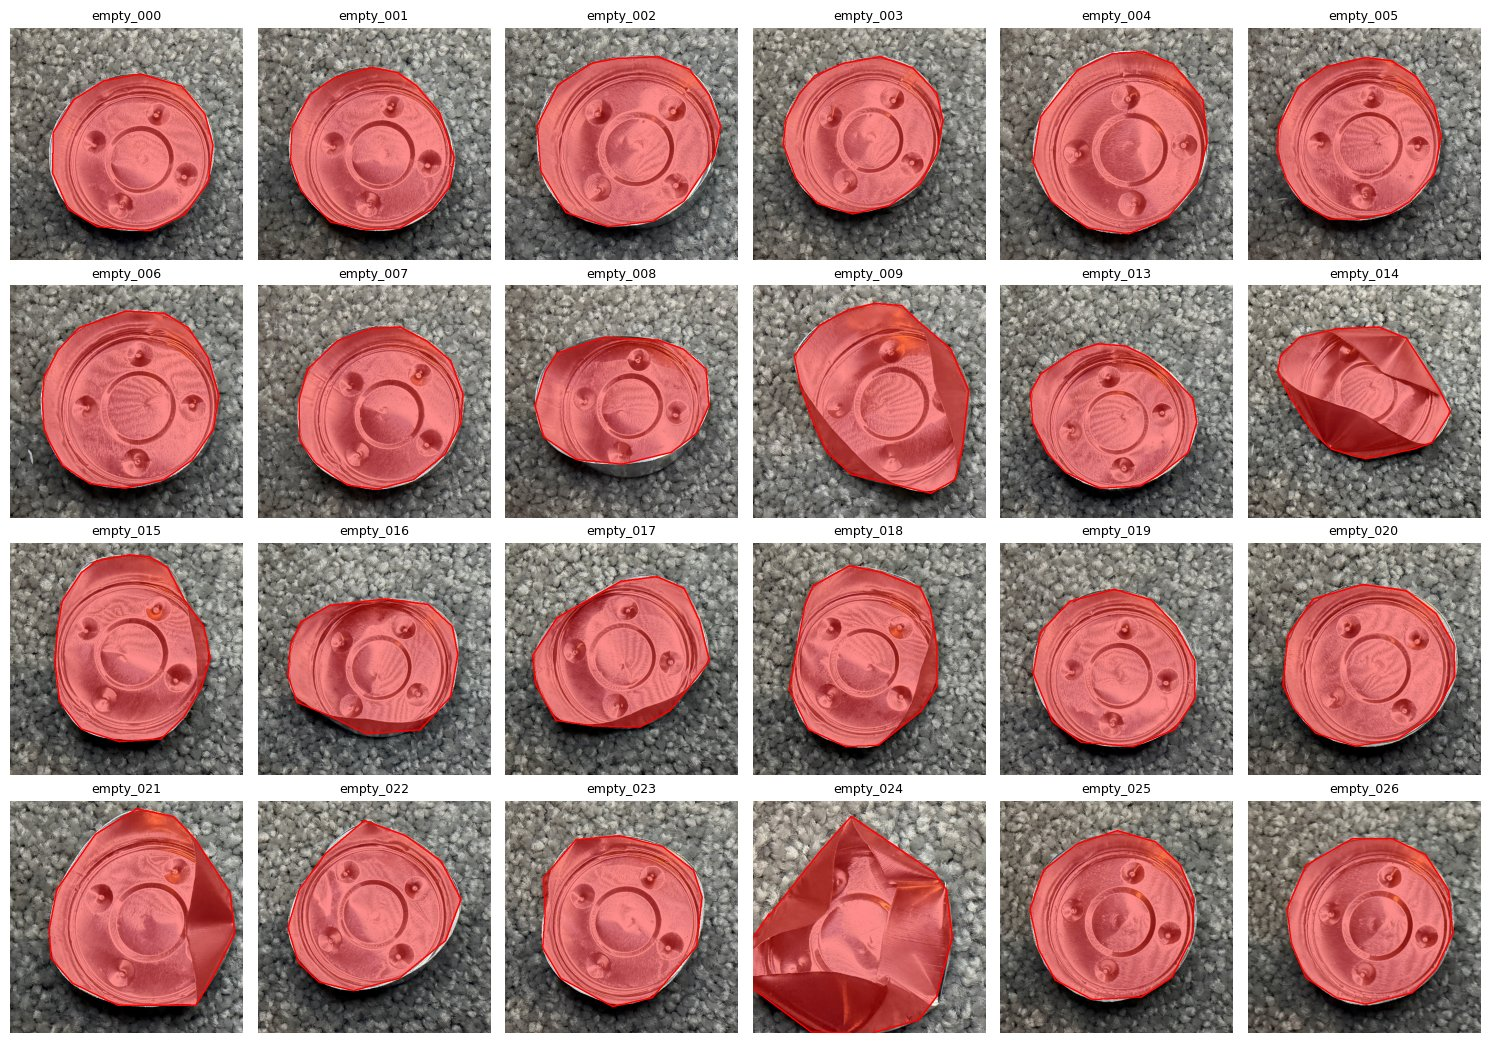

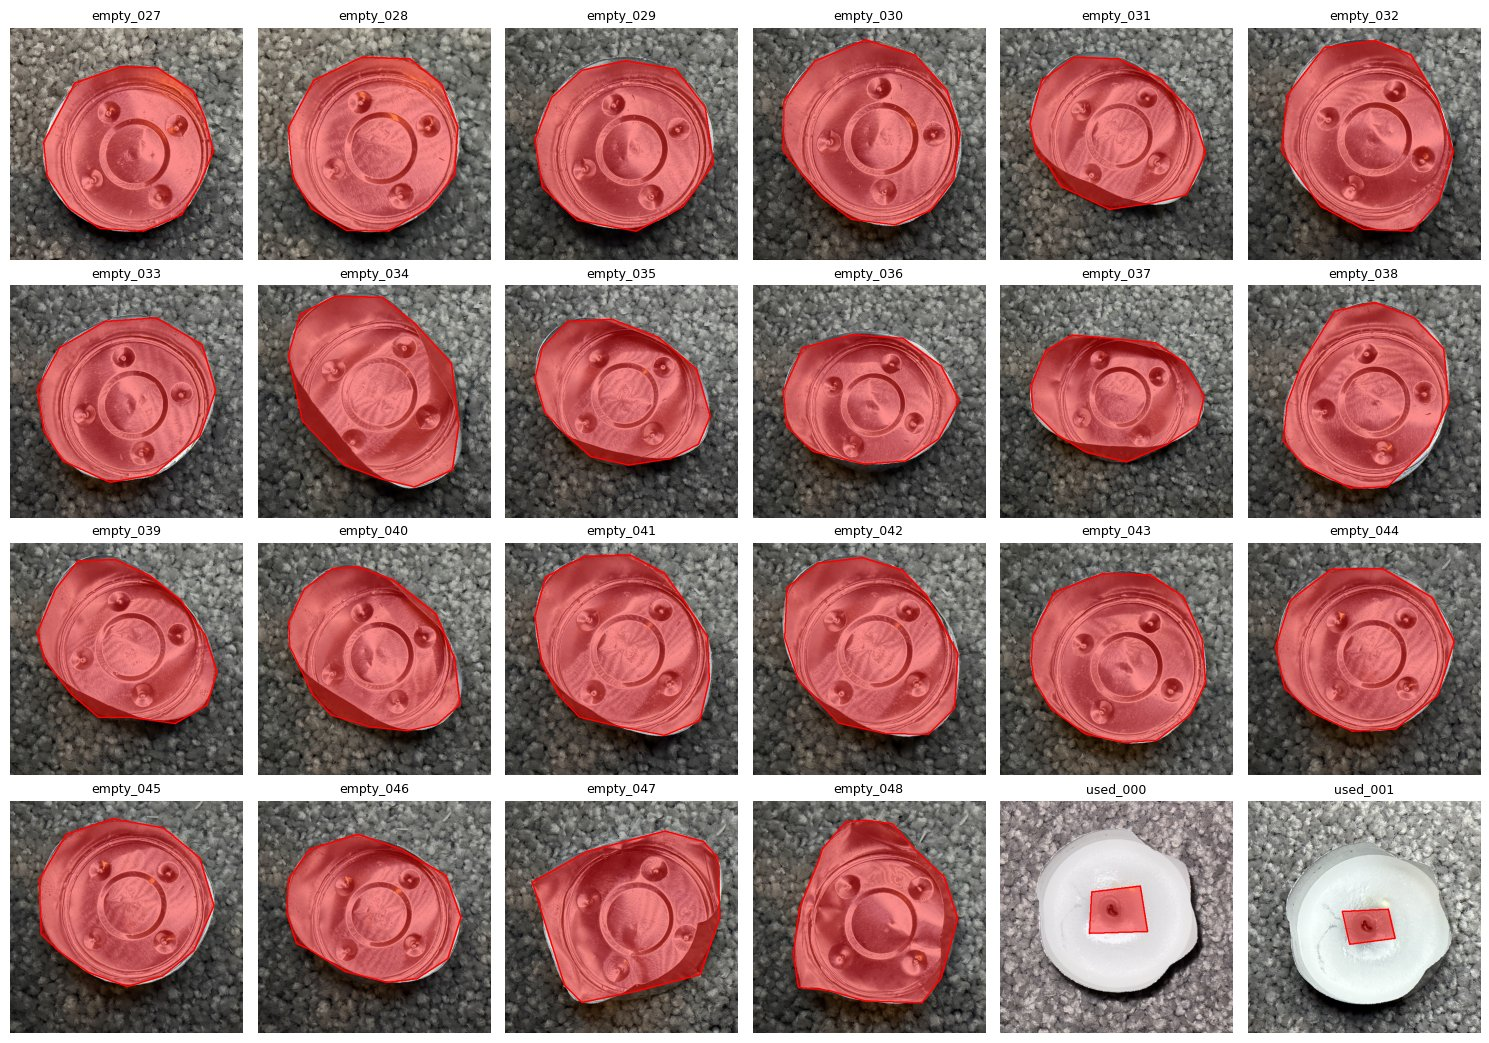

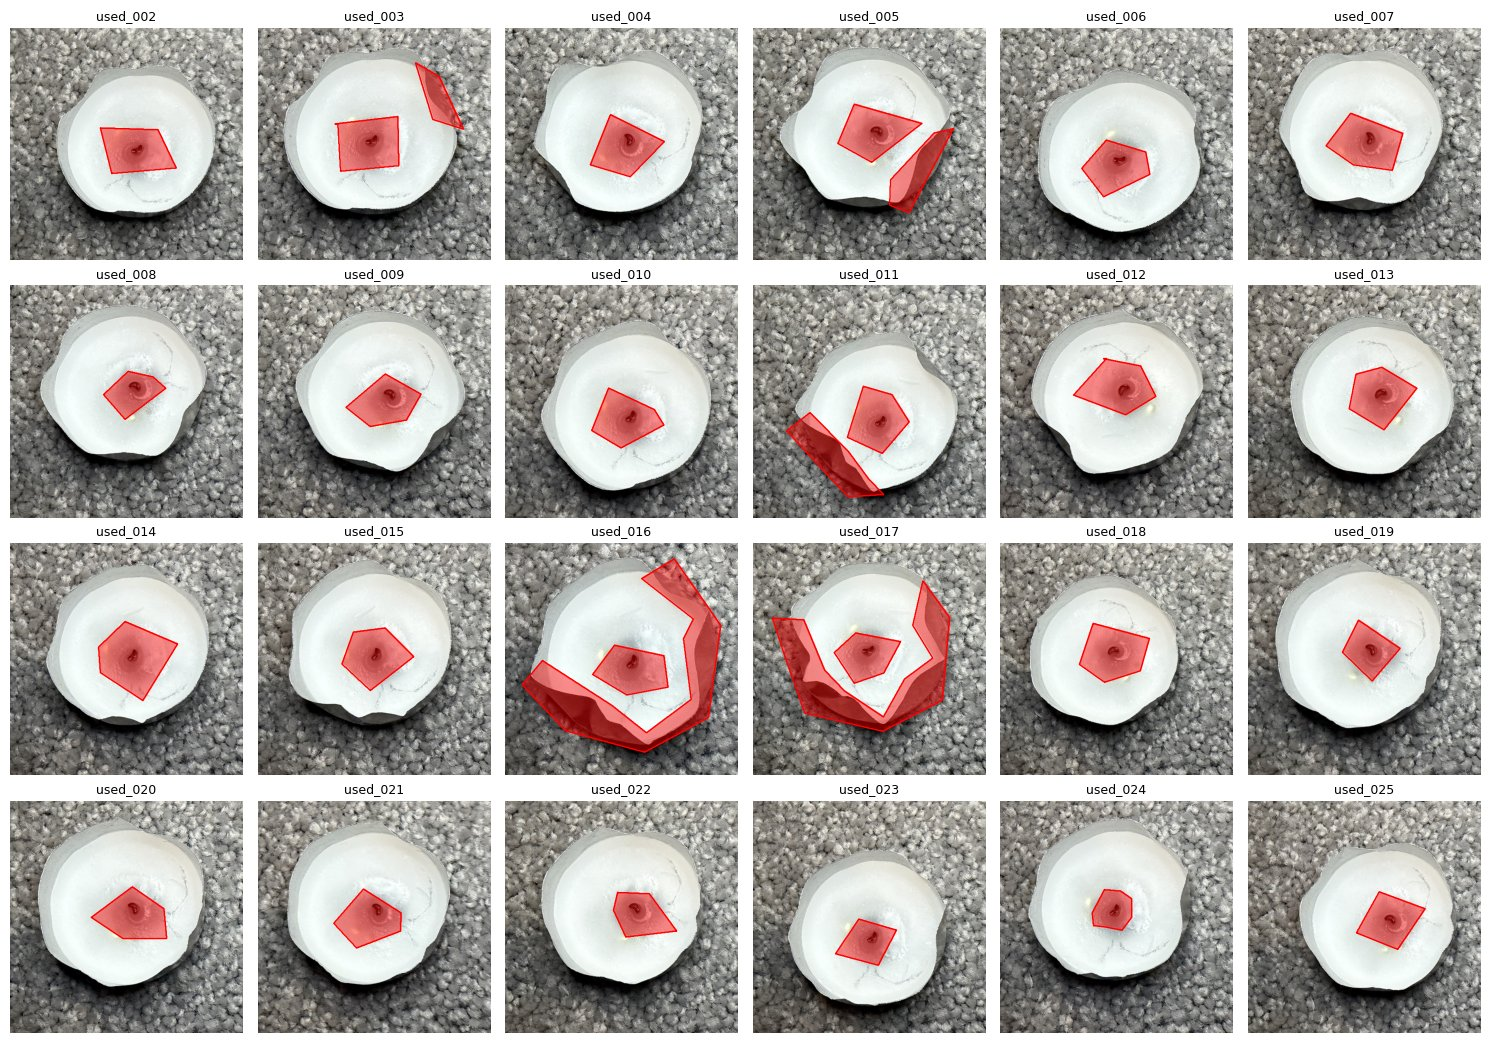

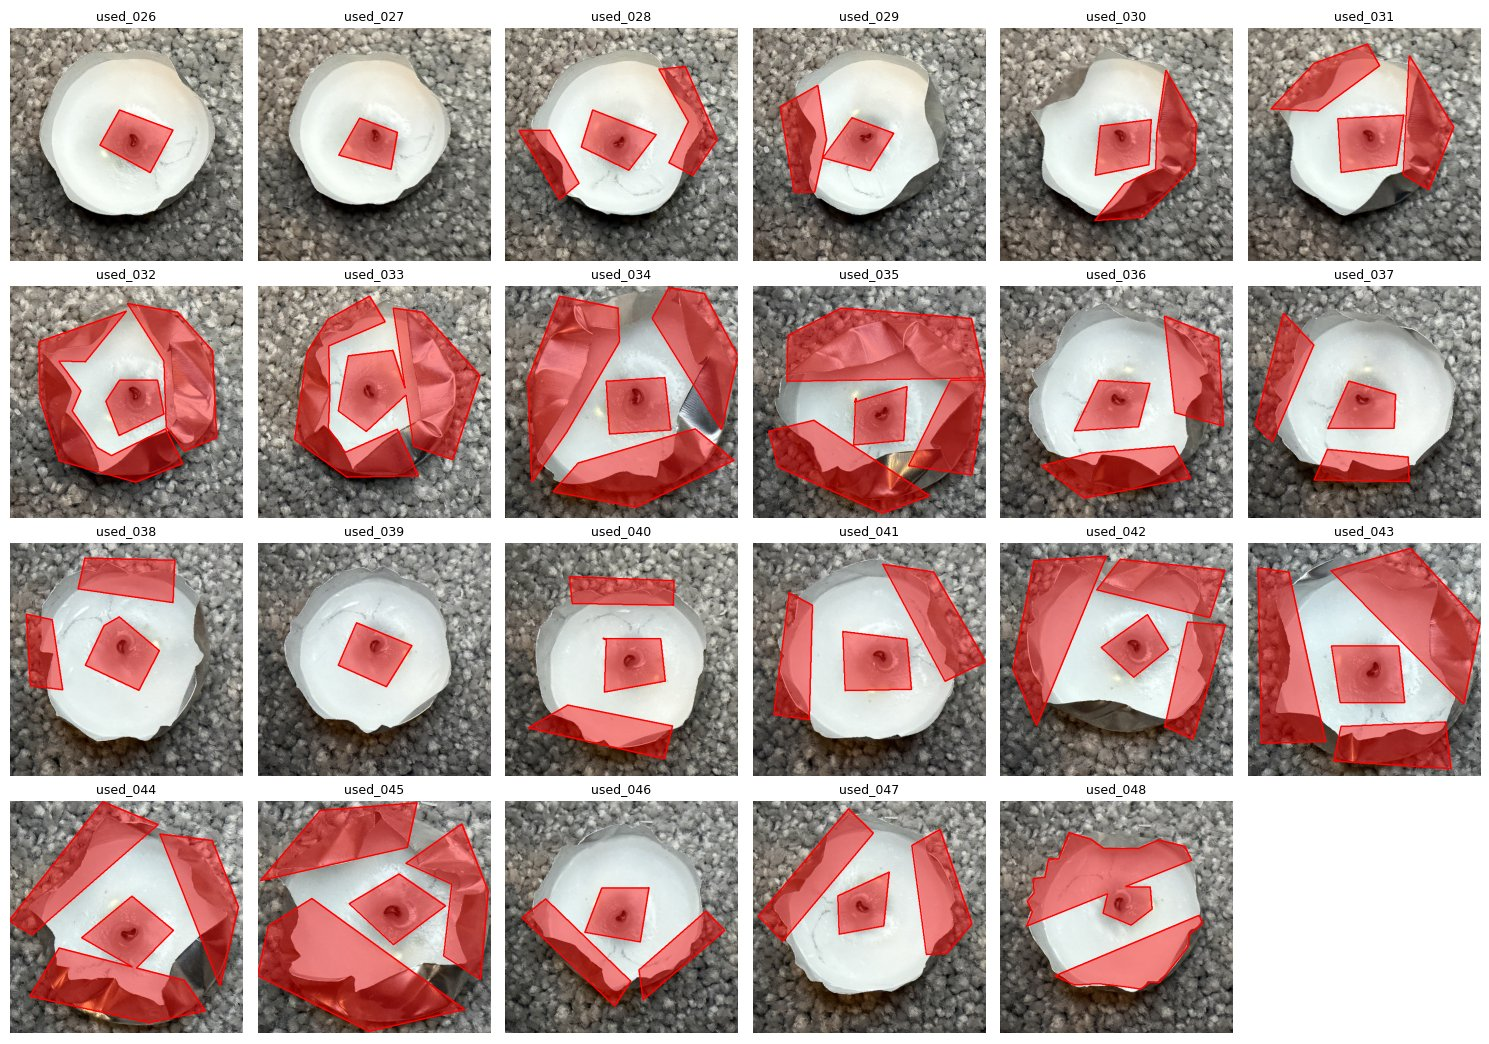

In [3]:
def overlay_sheets(mask_dict, tag, colour=(255, 0, 0)):
    names = sorted(mask_dict)
    for s in range(0, len(names), 24):
        fig, axes = plt.subplots(4, 6, figsize=(15, 10.5))
        for ax in axes.flat:
            ax.axis("off")
        for ax, n in zip(axes.flat, names[s:s + 24]):
            img = np.array(Image.open(f"{OUT}/test/{n.split('_')[0]}/{n}.png").convert("RGB"))
            m = mask_dict[n]
            img[m] = (0.55 * img[m] + 0.45 * np.array(colour)).astype(np.uint8)
            ax.imshow(img)
            ax.contour(m.astype(float), levels=[0.5], colors=[np.array(colour) / 255], linewidths=1)
            ax.set_title(n, fontsize=9)
        plt.tight_layout()
        plt.savefig(f"{ANN}/{tag}_{s // 24 + 1}.png", dpi=80)
        plt.show()

overlay_sheets(human, "mask_check")

# Part 2: Gemini as a second annotator


In [4]:
GEM = f"{ANN}/gemini_annotation"
shutil.rmtree(GEM, ignore_errors=True); os.makedirs(GEM)
from PIL import ImageFont
try:
    FONT = ImageFont.load_default(size=24)
except TypeError:
    FONT = ImageFont.load_default()

def prepare(img, image_id):
    im = img.convert("RGB").copy(); d = ImageDraw.Draw(im)
    for v in range(64, 512, 64):
        d.line([(v, 0), (v, 511)], fill=(255, 255, 0), width=1)
        d.line([(0, v), (511, v)], fill=(255, 255, 0), width=1)
        d.text((v + 2, 2), str(v), fill=(255, 255, 0))
        d.text((2, v + 2), str(v), fill=(255, 255, 0))
    d.rectangle([0, 476, 70, 511], fill="white")
    d.text((6, 480), image_id, fill="black", font=FONT)
    return im

PROMPT_ANNOT = '''You are annotating defects on photographs of tealight candles for a quality-control dataset. I am sending you several photographs. Each has an ID written in its bottom-left corner (for example a01). Annotate each photo on its own.

Each image is 512 x 512 pixels. Thin yellow grid lines are drawn every 64 pixels and labelled with their coordinates; x increases to the right and y increases downwards.

All of these are {kind} tealights, so every one is defective. On each photo, outline every defective region, following these guidelines:
- Empty tealights: outline the outer edge of the whole cup with one polygon, since the wax is missing everywhere. This includes any dents.
- Used tealights: outline the melted crater around the wick (the sunken or darker area, including the burnt wick and soot) with one polygon. Add a separate polygon for each folded part of the cup wall, where the grey outside of the aluminium is visible.
- Do not include the carpet, shadows, the thin silver rim seen on new tealights, or flat wax that looks unused.
Use one polygon per separate region, with 8 to 20 points going around its outline, in pixel coordinates of the 512 x 512 image.

For each photo, first write one short sentence describing the defects you see. Then finish your answer with one line per photo, each on a single line, in exactly this format:
a01: {{"polygons": [[[x1, y1], [x2, y2], ...], ...]}}'''

random.seed(0)
rows = []
for kind in ["used", "empty"]:
    names = sorted(n for n in human if n.startswith(kind))
    random.shuffle(names)
    rows += [{"name": n, "kind": kind} for n in names]
key = pd.DataFrame(rows)
key["id"] = [f"a{i + 1:02d}" for i in range(len(key))]
key["batch"] = 0
b = 0
for kind in ["used", "empty"]:
    idx = key.index[key.kind == kind]
    for j in range(0, len(idx), 10):
        b += 1
        key.loc[idx[j:j + 10], "batch"] = b

for r in key.itertuples():
    folder = f"{GEM}/batch_{r.batch:02d}_{r.kind}"
    os.makedirs(folder, exist_ok=True)
    prepare(Image.open(f"{OUT}/test/{r.kind}/{r.name}.png"), r.id).save(f"{folder}/{r.id}.png")
for kind in ["used", "empty"]:
    open(f"{GEM}/prompt_{kind}.txt", "w").write(PROMPT_ANNOT.format(kind=kind))
key.to_csv(f"{ANN}/gemini_annotation_key.csv", index=False)   # kept OUT of the upload folder

print("one message per batch: attach all images in the folder + paste the prompt for its kind")
for bt, g in key.groupby("batch"):
    print(f"  batch_{bt:02d}_{g.kind.iloc[0]}  ({len(g)} images: {g.id.iloc[0]}-{g.id.iloc[-1]})  ->  prompt_{g.kind.iloc[0]}.txt")

one message per batch: attach all images in the folder + paste the prompt for its kind
  batch_01_used  (10 images: a01-a10)  ->  prompt_used.txt
  batch_02_used  (10 images: a11-a20)  ->  prompt_used.txt
  batch_03_used  (10 images: a21-a30)  ->  prompt_used.txt
  batch_04_used  (10 images: a31-a40)  ->  prompt_used.txt
  batch_05_used  (9 images: a41-a49)  ->  prompt_used.txt
  batch_06_empty  (10 images: a50-a59)  ->  prompt_empty.txt
  batch_07_empty  (10 images: a60-a69)  ->  prompt_empty.txt
  batch_08_empty  (10 images: a70-a79)  ->  prompt_empty.txt
  batch_09_empty  (10 images: a80-a89)  ->  prompt_empty.txt
  batch_10_empty  (6 images: a90-a95)  ->  prompt_empty.txt


Gemeni Annotations


In [8]:
GEMINI_MODEL = "Gemini 3.6 Flash"
GEMINI_DATE = "2026-11-4"

GEMINI_ANNOT = r'''
### batch 01
Here are the descriptions of the defects and the corresponding annotations for each photograph:a01: The tealight has a central melted wax crater around a burnt wick and several bent/folded sections along its aluminum cup walls.
a02: The tealight exhibits a central melted crater around the burnt wick with slight wall decompressions.
a03: The tealight shows a sunken melted region in the center around the burnt wick and a folded aluminum cup edge.
a04: The tealight features a melted wax depression around the wick surrounded by partially deformed cup edges.
a05: The tealight contains a center melted crater and significant outer aluminum wall folds on the bottom right and left.
a06: The tealight displays a melted center crater around the wick and minor bending of the metal container wall.
a07: The tealight has a sunken melted wax crater surrounding the burnt wick at the center.
a08: The tealight shows a central melted crater and charred wick with minor indentations along the metal rim.
a09: The tealight exhibits a central melted crater around the wick along with heavily bent aluminum wall sections on the top-left.
a10: The tealight features a central melted crater around the wick and slight rim distortions.   a01: {"polygons": [[[240, 240], [270, 240], [285, 260], [280, 280], [250, 285], [230, 275], [230, 255]], [[80, 100], [130, 60], [180, 50], [125, 120], [80, 200], [68, 300], [70, 360], [110, 250], [90, 160]], [[380, 80], [420, 100], [480, 300], [450, 400], [400, 300], [400, 180]], [[190, 395], [240, 410], [240, 460], [200, 440], [190, 410]]]}
a02: {"polygons": [[[235, 235], [280, 235], [300, 265], [290, 300], [250, 310], [220, 290], [225, 255]]]}
a03: {"polygons": [[[225, 220], [275, 220], [290, 250], [280, 285], [240, 295], [215, 275], [210, 245]], [[380, 180], [430, 230], [420, 320], [390, 310], [395, 240]]]}
a04: {"polygons": [[[235, 225], [280, 225], [295, 255], [280, 290], [240, 295], [220, 270], [225, 240]]]}
a05: {"polygons": [[[230, 220], [275, 220], [295, 250], [280, 285], [240, 290], [215, 270], [215, 240]], [[390, 180], [465, 180], [470, 300], [430, 390], [390, 310], [440, 240]], [[190, 360], [300, 375], [315, 435], [200, 430]]]}
a06: {"polygons": [[[235, 225], [280, 220], [300, 250], [285, 285], [245, 290], [220, 270], [220, 245]]]}
a07: {"polygons": [[[215, 205], [265, 205], [280, 235], [270, 270], [230, 275], [205, 255], [205, 225]]]}
a08: {"polygons": [[[230, 210], [280, 210], [290, 240], [275, 275], [235, 280], [210, 260], [210, 230]]]}
a09: {"polygons": [[[210, 200], [260, 200], [275, 230], [265, 265], [225, 270], [200, 250], [200, 220]], [[125, 120], [190, 60], [130, 180], [60, 230], [90, 180]]]}
a10: {"polygons": [[[240, 230], [285, 230], [295, 260], [285, 295], [245, 300], [220, 275], [225, 245]]]}

### batch 02
Here are the defect annotations for each tealight candle photograph:   a11: photo a11 shows a heavily crushed metal cup with large folded aluminum walls and a central melted wax crater around the wick.
a11: {"polygons": [[[210, 205], [235, 200], [256, 208], [265, 240], [256, 260], [230, 262], [215, 248], [205, 222]], [[90, 195], [130, 375], [170, 395], [180, 290], [130, 260], [125, 215]], [[320, 65], [435, 190], [435, 305], [350, 315], [345, 185], [320, 75]], [[140, 395], [240, 415], [340, 415], [420, 400], [415, 345], [380, 300], [330, 320], [315, 370], [205, 380]]]}   a12: photo a12 shows a heavily bent tealight cup with silver aluminum folds on the sides and a central burnt wick crater.
a12: {"polygons": [[[230, 210], [270, 205], [305, 220], [315, 255], [310, 295], [270, 305], [235, 285], [220, 245]], [[65, 130], [200, 75], [190, 215], [165, 275], [130, 340], [65, 335], [75, 220]], [[385, 15], [450, 135], [500, 320], [450, 400], [405, 410], [385, 325], [445, 160], [395, 150]]]}   a13: photo a13 displays a used tealight candle with a slightly deformed rim and a small central melted depression surrounding the burnt wick.
a13: {"polygons": [[[230, 205], [270, 200], [295, 220], [290, 260], [260, 270], [230, 255], [220, 230], [225, 215]]]}   a14: photo a14 features a used tealight with slightly crimped edges and a darkened central wax crater around the wick.
a14: {"polygons": [[[215, 190], [255, 185], [285, 205], [290, 245], [275, 265], [245, 270], [215, 250], [205, 220]]]}   a15: photo a15 shows a tealight candle with a deformed rim and a distinct melted crater around the wick in the center.
a15: {"polygons": [[[210, 205], [245, 195], [280, 210], [290, 245], [275, 270], [240, 275], [210, 255], [200, 225]]]}   a16: photo a16 shows a used tealight candle with minor rim distortion and a clear central crater with soot around the wick.
a16: {"polygons": [[[205, 185], [245, 180], [270, 195], [275, 235], [260, 260], [230, 265], [205, 245], [195, 215]]]}   a17: photo a17 displays a used tealight with a slightly crumpled metallic side and a central melted pool around the burnt wick.
a17: {"polygons": [[[255, 270], [280, 265], [305, 280], [310, 310], [290, 335], [260, 335], [240, 315], [245, 290]]]}   a18: photo a18 shows a used tealight candle with a slightly uneven rim and a central melted crater containing soot and a burnt wick.
a18: {"polygons": [[[250, 270], [275, 265], [295, 280], [295, 310], [275, 330], [250, 330], [235, 310], [235, 285]]]}   a19: photo a19 displays a used tealight with a moderately warped metal lip and a clear central depression around the wick.
a19: {"polygons": [[[230, 235], [260, 230], [290, 245], [295, 275], [280, 305], [245, 310], [225, 290], [220, 260]]]}   a20: photo a20 features a used tealight candle with a slightly bent outer edge and a central melted crater surrounding the wick.
a20: {"polygons": [[[240, 220], [270, 215], [290, 230], [295, 265], [275, 290], [245, 290], [225, 270], [225, 240]]]}

### batch 03
a21
The image shows a used tealight with a sunken melted central crater around a burnt wick and a fold in the outer aluminum casing at the bottom left.
a21: {"polygons": [[[248, 224], [285, 222], [315, 238], [320, 269], [298, 302], [257, 311], [225, 290], [220, 255]], [[80, 275], [105, 185], [125, 148], [112, 235], [96, 310]]]}   a22
The photo depicts a used tealight candle with a charred wick within a sunken melted area.
a22: {"polygons": [[[242, 212], [280, 215], [305, 238], [312, 272], [288, 305], [245, 312], [215, 288], [212, 248]]]}   a23
The photo features a used tealight candle with a sunken central crater around the burnt wick and a fold on the metal wall near the bottom.
a23: {"polygons": [[[236, 216], [275, 218], [308, 242], [315, 276], [285, 312], [240, 316], [205, 285], [208, 248]], [[112, 315], [138, 215], [170, 142], [140, 242], [120, 345]]]}   a24
The image displays a used tealight candle with a central melted depression around its burnt wick.
a24: {"polygons": [[[230, 210], [272, 212], [302, 238], [308, 275], [280, 308], [238, 312], [205, 282], [208, 242]]]}   a25
The photo shows a used tealight candle with a sunken central crater containing a burnt wick.
a25: {"polygons": [[[240, 205], [280, 208], [310, 232], [318, 268], [290, 302], [242, 308], [210, 280], [212, 238]]]}   a26
The image exhibits a used tealight candle with a melted center area, burnt wick, and a slightly deformed aluminum rim.
a26: {"polygons": [[[235, 212], [278, 215], [305, 238], [312, 272], [285, 305], [240, 310], [210, 282], [212, 242]]]}   a27
The photo shows a used tealight candle with a charred wick at the center of a melted crater.
a27: {"polygons": [[[238, 215], [278, 218], [306, 242], [312, 275], [286, 308], [242, 312], [210, 285], [212, 248]]]}   a28
The photo shows a used tealight candle with a burnt wick in a central depression and a heavily folded top aluminum rim bend.
a28: {"polygons": [[[242, 208], [282, 212], [310, 235], [318, 270], [290, 302], [245, 308], [212, 278], [215, 238]], [[132, 60], [245, 52], [315, 105], [245, 115], [150, 108]]]}   a29
The image reveals a used tealight candle with a melted central depression holding a burnt wick.
a29: {"polygons": [[[232, 202], [272, 205], [302, 228], [308, 262], [282, 295], [238, 300], [205, 272], [208, 232]]]}   a30
The photo illustrates a used tealight candle with a sunken central crater and burnt wick, alongside a folded rim area at the lower left bottom.
a30: {"polygons": [[[230, 212], [270, 215], [298, 238], [305, 270], [278, 302], [235, 308], [202, 280], [205, 242]], [[160, 345], [245, 395], [300, 422], [235, 412], [178, 385]]]}

### batch 04

Here are the descriptions and defect annotations for each image:   a31: The candle has a central melted crater around a burnt wick with slight soot, and the aluminum wall shows mild deformation around its edges.
a31: {"polygons": [[[232, 218], [266, 216], [280, 235], [275, 260], [250, 268], [225, 258], [220, 238]]]}   a32: The candle features a central melted crater and wick, surrounded by heavily folded metallic rim sections covering the outer perimeter.
a32: {"polygons": [[[262, 222], [286, 222], [305, 236], [308, 260], [288, 276], [260, 272], [250, 252]], [[260, 24], [352, 64], [448, 128], [500, 268], [488, 384], [384, 488], [240, 480], [120, 432], [76, 264], [64, 184], [104, 160], [240, 144]]]}   a33: The tealight has a melted crater with a burnt wick in the middle and minor warping along the upper aluminum rim.
a33: {"polygons": [[[236, 232], [268, 232], [284, 250], [276, 276], [252, 284], [230, 274], [224, 252]]]}   a34: The candle shows a central melted crater around the wick and several heavily bent metallic wall regions along the rim.
a34: {"polygons": [[[256, 256], [282, 254], [298, 272], [290, 294], [266, 302], [246, 292], [242, 272]], [[248, 76], [352, 104], [440, 216], [488, 328], [440, 432], [312, 472], [232, 448], [112, 328], [100, 204], [168, 188], [232, 168]]]}   a35: The tealight contains a central melted wax crater around a burnt wick with a light rim bend.
a35: {"polygons": [[[224, 212], [254, 210], [270, 228], [264, 252], [240, 260], [218, 250], [212, 230]]]}   a36: The candle has a prominent melted central crater around the wick with minor surface deformation along the cup's outer edge.
a36: {"polygons": [[[248, 198], [280, 196], [296, 216], [290, 242], [266, 252], [242, 242], [236, 218]]]}   a37: The candle displays a melted central crater with soot and large folded foil sections along the lower and side edges.
a37: {"polygons": [[[230, 260], [262, 258], [276, 276], [270, 298], [246, 306], [224, 296], [218, 276]], [[200, 36], [328, 52], [424, 116], [488, 236], [480, 360], [424, 464], [280, 496], [160, 432], [88, 312], [84, 204], [168, 180]]]}   a38: The candle features a sunken melted crater around a burnt wick and light crushing along the rim.
a38: {"polygons": [[[264, 210], [294, 208], [310, 226], [304, 250], [280, 258], [258, 248], [252, 228]]]}   a39: The tealight has a melted central crater around the wick with a slightly crushed upper rim area.
a39: {"polygons": [[[224, 228], [256, 226], [270, 244], [264, 268], [240, 276], [218, 266], [212, 246]]]}   a40: The candle has a central melted crater containing the burnt wick surrounded by a smooth rim.
a40: {"polygons": [[[258, 216], [288, 214], [304, 232], [298, 256], [274, 264], [252, 254], [246, 234]]]}


### batch 05
Here are the descriptions and defect annotations for each tealight image:

a41
The tealight has a melted central crater with a burnt wick and heavily folded aluminium cup walls on the right side.
a41: {"polygons": [[[230, 202], [285, 202], [320, 222], [338, 256], [320, 290], [285, 305], [230, 305], [200, 280], [190, 250], [200, 220]], [[348, 102], [412, 180], [420, 298], [384, 320], [352, 285], [350, 215]]]}

a42
The tealight features a central melted crater around the charred wick and mild rim warping.
a42: {"polygons": [[[228, 205], [285, 205], [320, 225], [335, 256], [320, 288], [285, 302], [230, 302], [200, 280], [192, 256], [202, 225]]]}

a43
The tealight displays a melted crater around the burnt wick with slight rim indentation.
a43: {"polygons": [[[290, 200], [345, 200], [380, 225], [395, 256], [380, 288], [345, 308], [290, 308], [260, 285], [250, 256], [260, 222]]]}

a44
The tealight has a melted center crater surrounding the burnt wick and prominent folds along the right outer edge of the metal cup.
a44: {"polygons": [[[230, 202], [285, 202], [320, 222], [338, 256], [320, 290], [285, 305], [230, 305], [200, 280], [190, 250], [200, 220]], [[348, 102], [412, 180], [420, 298], [384, 320], [352, 285], [350, 215]]]}

a45
The tealight exhibits a central melted crater around the wick and several large folded sections of the aluminium wall.
a45: {"polygons": [[[235, 200], [290, 200], [325, 222], [340, 256], [325, 290], [290, 308], [235, 308], [205, 285], [195, 256], [205, 222]], [[355, 128], [445, 170], [448, 290], [390, 345], [355, 305], [352, 215]], [[70, 145], [128, 130], [130, 280], [105, 390], [70, 310]]]}

a46
The tealight has a central melted crater with a dark burnt wick and notable folds on the bottom and right edges of the metal cup.
a46: {"polygons": [[[240, 205], [295, 205], [330, 228], [342, 256], [330, 288], [295, 305], [240, 305], [210, 282], [200, 256], [210, 225]], [[125, 310], [190, 335], [295, 435], [200, 435], [140, 380]], [[415, 145], [465, 280], [440, 380], [415, 330], [418, 220]]]}

a47
The tealight shows a sunken melted crater with a burnt wick in the middle.
a47: {"polygons": [[[238, 202], [292, 202], [328, 225], [340, 256], [328, 288], [292, 305], [238, 305], [208, 282], [198, 256], [208, 222]]]}

a48
The tealight contains a central melted crater with a charred wick.
a48: {"polygons": [[[232, 202], [288, 202], [322, 222], [336, 256], [322, 288], [288, 305], [232, 305], [202, 282], [192, 256], [202, 222]]]}

a49
The tealight presents a central melted crater around the wick and minor uneven edges along the rim.
a49: {"polygons": [[[230, 200], [285, 200], [320, 220], [335, 256], [320, 288], [285, 305], [230, 305], [200, 280], [190, 256], [200, 220]]]}

### batch 06
a50: The image shows an empty, deformed aluminium tealight cup missing all wax, with flattened outer edges.
a50: {"polygons": [[[134, 439], [103, 376], [80, 273], [105, 185], [178, 137], [321, 135], [411, 169], [442, 239], [441, 319], [410, 372], [330, 422], [222, 429]]]}   a51: The image depicts an empty aluminium tealight casing devoid of wax, featuring bent rim walls.
a51: {"polygons": [[[112, 342], [101, 232], [146, 151], [227, 107], [319, 105], [403, 134], [445, 203], [442, 303], [399, 381], [331, 433], [242, 442], [163, 408]]]}   a52: The image shows a completely empty tealight cup with deformed edges and no wax present.
a52: {"polygons": [[[112, 360], [93, 237], [131, 127], [218, 70], [330, 72], [416, 128], [447, 240], [442, 345], [401, 412], [325, 442], [231, 423], [152, 396]]]}   a53: The image shows an empty, crumpled tealight aluminum container without wax.
a53: {"polygons": [[[159, 391], [80, 246], [84, 186], [161, 134], [299, 81], [408, 93], [470, 163], [471, 252], [427, 335], [376, 404], [289, 442], [206, 440]]]}   a54: The image depicts an empty metal tealight casing missing wax, with a pinched top point.
a54: {"polygons": [[[112, 311], [83, 218], [128, 117], [214, 53], [299, 83], [400, 117], [439, 198], [440, 290], [393, 376], [296, 414], [182, 396], [131, 357]]]}   a55: The image shows a severely bent and crushed empty tealight cup with no remaining wax.
a55: {"polygons": [[[173, 364], [78, 222], [97, 149], [228, 112], [361, 135], [443, 253], [435, 338], [342, 379], [260, 363], [191, 375]]]}   a56: The image shows a round, empty aluminium tealight container completely devoid of wax.
a56: {"polygons": [[[132, 378], [80, 269], [99, 161], [184, 91], [302, 79], [406, 112], [451, 187], [451, 301], [401, 390], [314, 439], [212, 440], [151, 409]]]}   a57: The image features an empty tealight cup with a misshapen rim and no wax inside.
a57: {"polygons": [[[158, 321], [78, 203], [124, 88], [215, 35], [330, 69], [419, 143], [447, 241], [442, 338], [392, 381], [276, 380], [198, 357]]]}   a58: The image shows an empty tealight shell missing its wax content, with slightly warped sides.
a58: {"polygons": [[[141, 364], [78, 250], [92, 147], [178, 80], [295, 71], [396, 101], [445, 172], [447, 277], [408, 368], [328, 412], [229, 412], [163, 388]]]}   a59: The image shows a flattened, empty tealight cup completely lacking wax.
a59: {"polygons": [[[118, 338], [80, 228], [116, 140], [200, 122], [318, 122], [415, 142], [437, 219], [435, 312], [395, 387], [295, 423], [199, 388], [140, 368]]]}

### batch 07

This image shows an empty, deformed tealight cup.
a60: {"polygons": [[[256, 76], [320, 80], [384, 115], [420, 160], [424, 256], [420, 340], [384, 400], [320, 420], [256, 424], [180, 400], [140, 320], [132, 230], [160, 140], [210, 90]]]}   This image shows an empty tealight cup with a major dent folded inward on the right side.
a61: {"polygons": [[[256, 26], [320, 32], [384, 64], [400, 120], [394, 200], [376, 256], [490, 260], [492, 330], [440, 420], [384, 440], [320, 456], [256, 456], [192, 420], [168, 330], [180, 230], [256, 120], [210, 60]]]}   This image shows an empty, deformed tealight cup with bent edges.
a62: {"polygons": [[[256, 46], [320, 56], [384, 100], [440, 192], [448, 280], [420, 360], [370, 410], [300, 440], [230, 420], [160, 360], [150, 256], [170, 160], [210, 80]]]}   This image shows an empty, warped tealight cup.
a63: {"polygons": [[[256, 36], [330, 44], [390, 80], [430, 130], [456, 210], [456, 310], [430, 390], [360, 440], [270, 448], [190, 400], [130, 300], [130, 200], [180, 90]]]}   This image shows an empty tealight cup with minor edge deformations.
a64: {"polygons": [[[256, 110], [320, 115], [384, 140], [420, 190], [430, 256], [420, 340], [390, 400], [320, 430], [256, 436], [180, 410], [136, 330], [132, 230], [160, 140], [200, 115]]]}   This image shows a heavily crushed and flattened empty tealight cup.
a65: {"polygons": [[[210, 140], [290, 132], [370, 150], [444, 210], [444, 290], [390, 344], [290, 384], [180, 350], [130, 310], [130, 220], [160, 160]]]}   This image shows a round, empty tealight cup.
a66: {"polygons": [[[256, 92], [320, 96], [384, 130], [430, 190], [440, 270], [420, 350], [370, 410], [300, 440], [220, 430], [150, 370], [132, 270], [150, 170], [192, 115]]]}   This image shows an empty tealight cup with minor distortion.
a67: {"polygons": [[[256, 70], [320, 76], [384, 110], [424, 170], [424, 260], [410, 340], [370, 400], [300, 430], [230, 420], [160, 370], [130, 270], [150, 160], [192, 90]]]}   This image shows a squashed, oval-shaped empty tealight cup.
a68: {"polygons": [[[230, 64], [310, 76], [390, 130], [450, 240], [450, 320], [400, 390], [300, 415], [200, 370], [140, 300], [130, 200], [160, 110]]]}   This image shows an empty, crushed tealight cup.
a69: {"polygons": [[[256, 100], [320, 105], [384, 140], [440, 210], [448, 290], [410, 370], [340, 410], [256, 400], [180, 350], [130, 270], [132, 170], [180, 115]]]}

### batch 08

The empty tealight cups in these photos are completely missing their wax, displaying exposed metal bases and deformed rim structures.   a70: {"polygons": [[[248, 166], [168, 235], [178, 381], [220, 482], [328, 529], [421, 528], [500, 469], [538, 383], [521, 281], [461, 212], [376, 178], [299, 163]]]}
a71: {"polygons": [[[236, 148], [153, 206], [140, 310], [165, 410], [228, 497], [306, 529], [399, 509], [480, 439], [535, 345], [524, 239], [472, 169], [389, 137], [302, 133]]]}
a72: {"polygons": [[[256, 185], [164, 256], [148, 370], [182, 477], [250, 539], [354, 560], [459, 520], [536, 423], [546, 316], [512, 218], [437, 169], [339, 161]]]}
a73: {"polygons": [[[256, 187], [168, 260], [158, 375], [198, 479], [279, 550], [387, 560], [479, 514], [551, 417], [561, 311], [521, 214], [438, 185], [337, 185]]]}
a74: {"polygons": [[[132, 142], [144, 284], [230, 429], [347, 508], [476, 519], [534, 442], [546, 320], [488, 227], [379, 169], [253, 143]]]}
a75: {"polygons": [[[248, 132], [150, 197], [131, 326], [168, 451], [250, 509], [339, 508], [436, 458], [509, 362], [520, 241], [474, 160], [382, 131], [299, 127]]]}
a76: {"polygons": [[[215, 203], [134, 288], [131, 403], [180, 483], [260, 526], [361, 517], [452, 461], [538, 375], [558, 274], [525, 208], [438, 198], [311, 198]]]}
a77: {"polygons": [[[251, 204], [160, 280], [140, 396], [178, 497], [254, 558], [349, 560], [438, 517], [520, 426], [541, 312], [506, 218], [415, 203], [325, 201]]]}
a78: {"polygons": [[[246, 255], [153, 316], [134, 427], [172, 532], [248, 592], [342, 592], [436, 545], [518, 452], [539, 338], [507, 255], [422, 250], [323, 252]]]}
a79: {"polygons": [[[248, 131], [150, 196], [131, 325], [170, 452], [251, 511], [339, 508], [436, 458], [509, 362], [520, 241], [474, 160], [382, 131], [299, 127]]]}

### batch 09

Here are the descriptions and single-line polygon annotations for each empty tealight photo based on the outer edge guidelines provided:

Descriptions
a80: An empty, mostly round silver aluminium tealight cup.

a81: An empty, squished oval aluminium tealight cup.

a82: An empty, bent aluminium tealight cup with folded sides.

a83: An empty oval aluminium tealight cup.

a84: An empty, slightly deformed oval aluminium tealight cup.

a85: An empty aluminium tealight cup with a slightly flattened top rim.

a86: An empty, nearly circular aluminium tealight cup.

a87: An empty aluminium tealight cup with a bent rim on the top-left edge.

a88: An empty oval aluminium tealight cup.

a89: A heavily crushed and flattened aluminium tealight cup with wide folded sides.

Annotations
a80: {"polygons": [[[212, 60], [314, 60], [398, 92], [440, 150], [452, 230], [442, 310], [405, 380], [338, 432], [252, 442], [182, 400], [132, 310], [130, 222], [165, 126], [212, 60]]]}
a81: {"polygons": [[[212, 62], [320, 110], [402, 185], [440, 260], [445, 320], [382, 388], [286, 400], [188, 320], [131, 230], [130, 140], [178, 76], [212, 62]]]}
a82: {"polygons": [[[282, 42], [378, 122], [460, 226], [472, 338], [442, 422], [342, 442], [248, 388], [180, 282], [180, 172], [230, 80], [282, 42]]]}
a83: {"polygons": [[[232, 32], [326, 68], [398, 138], [438, 222], [445, 308], [435, 392], [372, 428], [278, 380], [188, 298], [130, 192], [132, 100], [188, 46], [232, 32]]]}
a84: {"polygons": [[[262, 70], [345, 88], [412, 132], [442, 212], [432, 308], [398, 362], [312, 400], [222, 392], [138, 312], [128, 222], [172, 138], [262, 70]]]}
a85: {"polygons": [[[212, 28], [305, 28], [375, 80], [425, 170], [428, 280], [410, 368], [342, 432], [262, 430], [202, 360], [198, 240], [215, 122], [212, 28]]]}
a86: {"polygons": [[[272, 52], [360, 80], [425, 138], [450, 220], [438, 318], [390, 392], [312, 442], [222, 442], [148, 380], [138, 270], [170, 160], [218, 82], [272, 52]]]}
a87: {"polygons": [[[235, 78], [325, 82], [392, 115], [435, 172], [442, 270], [420, 372], [338, 442], [230, 442], [168, 372], [152, 270], [185, 150], [235, 78]]]}
a88: {"polygons": [[[222, 50], [315, 62], [390, 128], [402, 230], [382, 335], [320, 420], [220, 442], [170, 388], [165, 280], [188, 162], [222, 50]]]}
a89: {"polygons": [[[212, 30], [262, 102], [420, 172], [428, 290], [420, 370], [402, 448], [288, 508], [212, 508], [112, 452], [0, 330], [0, 292], [132, 80], [212, 30]]]}
### batch 10
The photographs show empty tealight candle cups with various degrees of deformation.

a90: The photo shows an empty, deformed silver tealight cup.
a90: {"polygons": [[[215, 27], [351, 31], [437, 237], [436, 381], [342, 451], [257, 423], [148, 269], [134, 116]]]}

a91: The photo shows an empty, deformed silver tealight cup.
a91: {"polygons": [[[129, 64], [256, 30], [384, 88], [448, 230], [448, 384], [351, 428], [242, 380], [130, 265], [128, 128]]]}

a92: The photo shows an empty, slightly deformed silver tealight cup.
a92: {"polygons": [[[173, 102], [300, 102], [427, 128], [448, 256], [427, 384], [300, 448], [173, 410], [173, 256]]]}

a93: The photo shows an empty, deformed silver tealight cup.
a93: {"polygons": [[[132, 66], [260, 66], [388, 128], [448, 256], [448, 384], [320, 440], [192, 388], [132, 256]]]}

a94: The photo shows an empty, deformed silver tealight cup.
a94: {"polygons": [[[132, 48], [260, 48], [388, 70], [448, 192], [448, 320], [320, 404], [192, 360], [132, 232]]]}

a95: The photo shows an empty, crushed and flattened silver tealight cup.
a95: {"polygons": [[[188, 48], [320, 48], [420, 110], [448, 240], [420, 390], [290, 444], [188, 410], [188, 240]]]}
'''

open(f"{ANN}/gemini_annotation_answers.txt", "w").write(GEMINI_ANNOT)
json.dump({"model": GEMINI_MODEL, "date": GEMINI_DATE,
           "interface": "Gemini web app, default settings, 10 images per message, new chat per batch"},
          open(f"{ANN}/gemini_annotation_setup.json", "w"), indent=2)

def find_json_after(text, start):
    i = text.find("{", start)
    if i < 0 or i - start > 15:
        return None
    depth = 0
    for j in range(i, len(text)):
        depth += {"{": 1, "}": -1}.get(text[j], 0)
        if depth == 0:
            return text[i:j + 1]
    return None

answers = {}
for m in re.finditer(r"\b(a\d{2})\**\s*[:\-]", GEMINI_ANNOT):
    js = find_json_after(GEMINI_ANNOT, m.end())
    if js and '"polygons"' in js:
        answers[m.group(1)] = js
print(len(answers), "/ 95 answers found; missing:", sorted(set(key.id) - set(answers)))

95 / 95 answers found; missing: []


answers that couldn't be read (no polygons): []


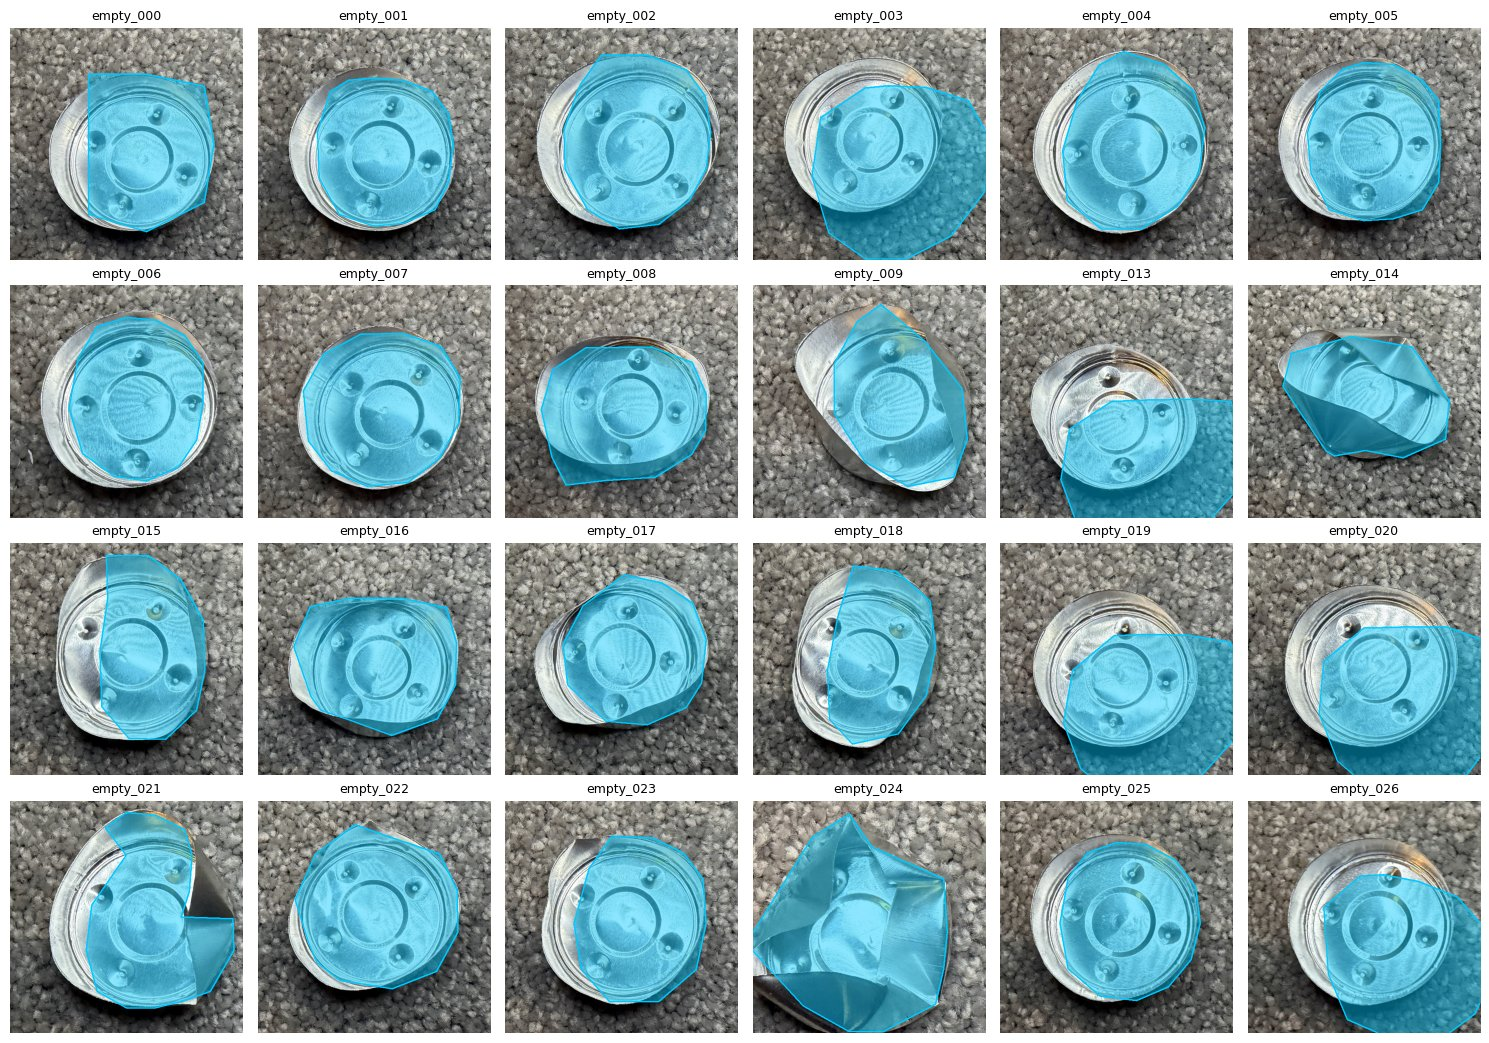

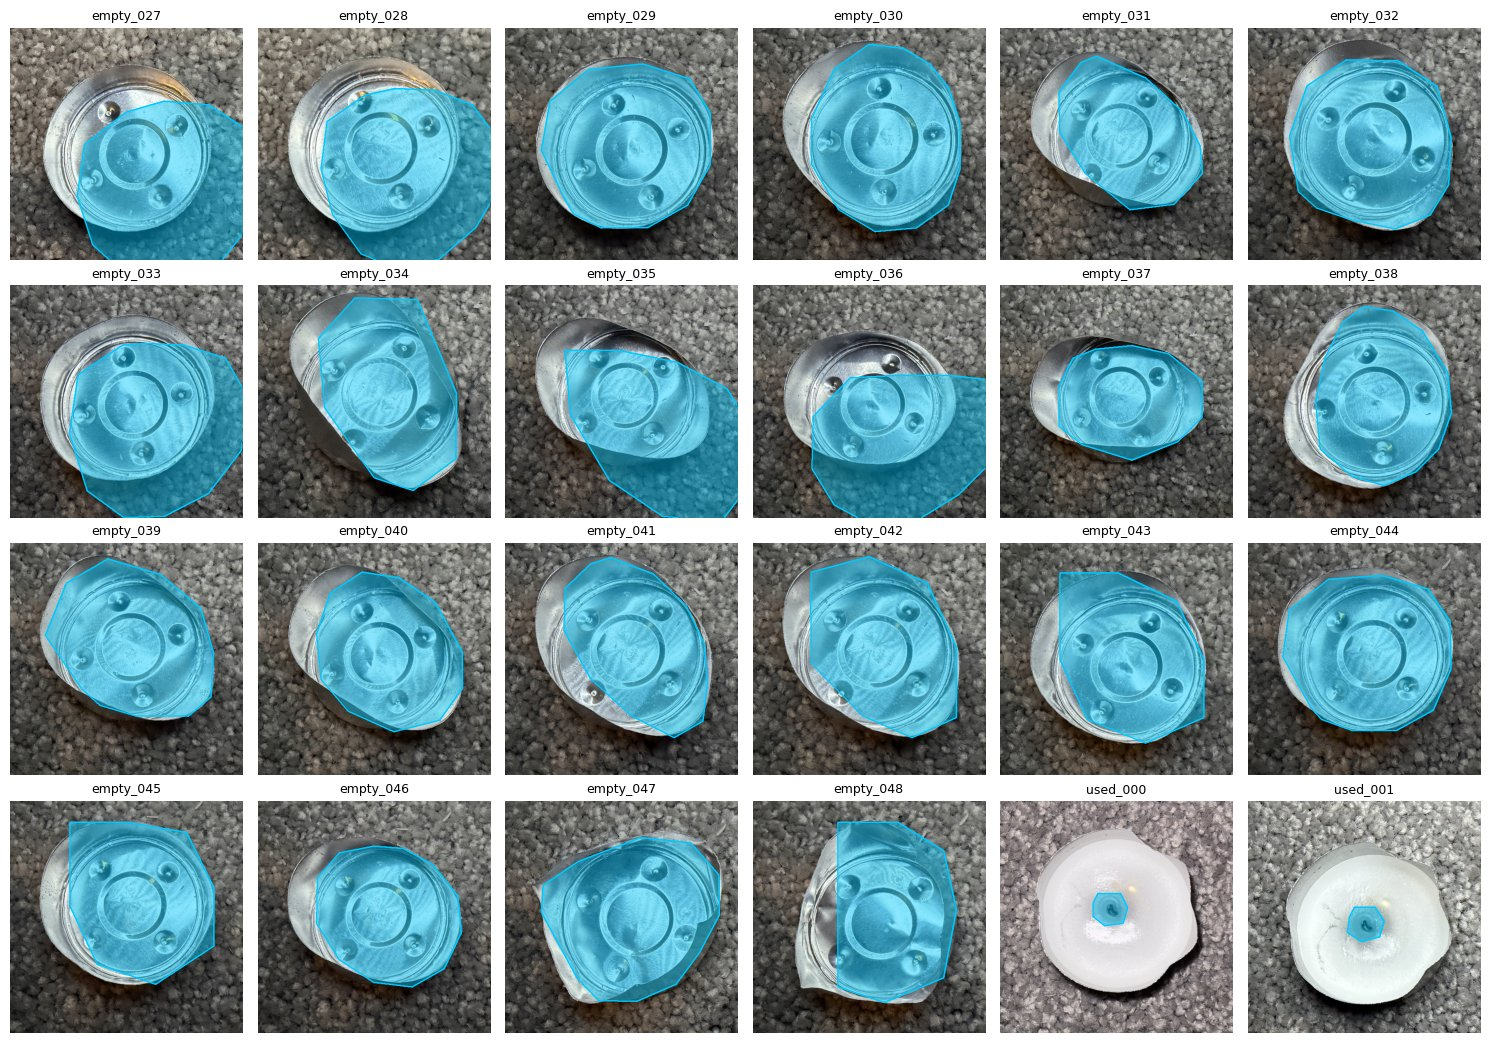

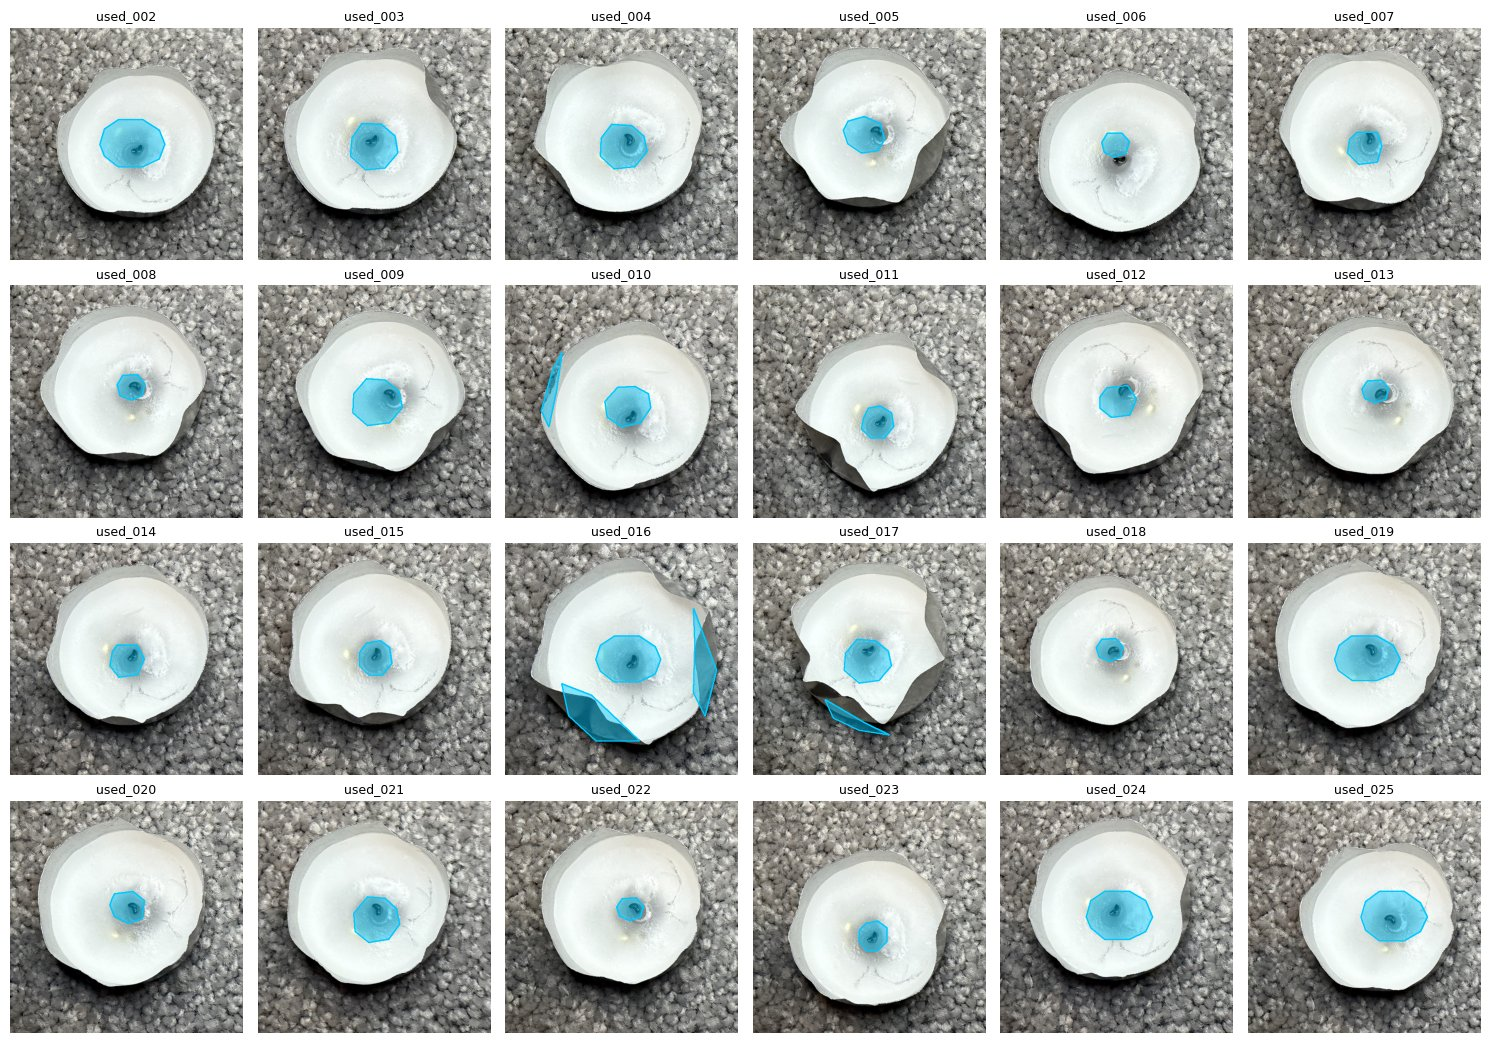

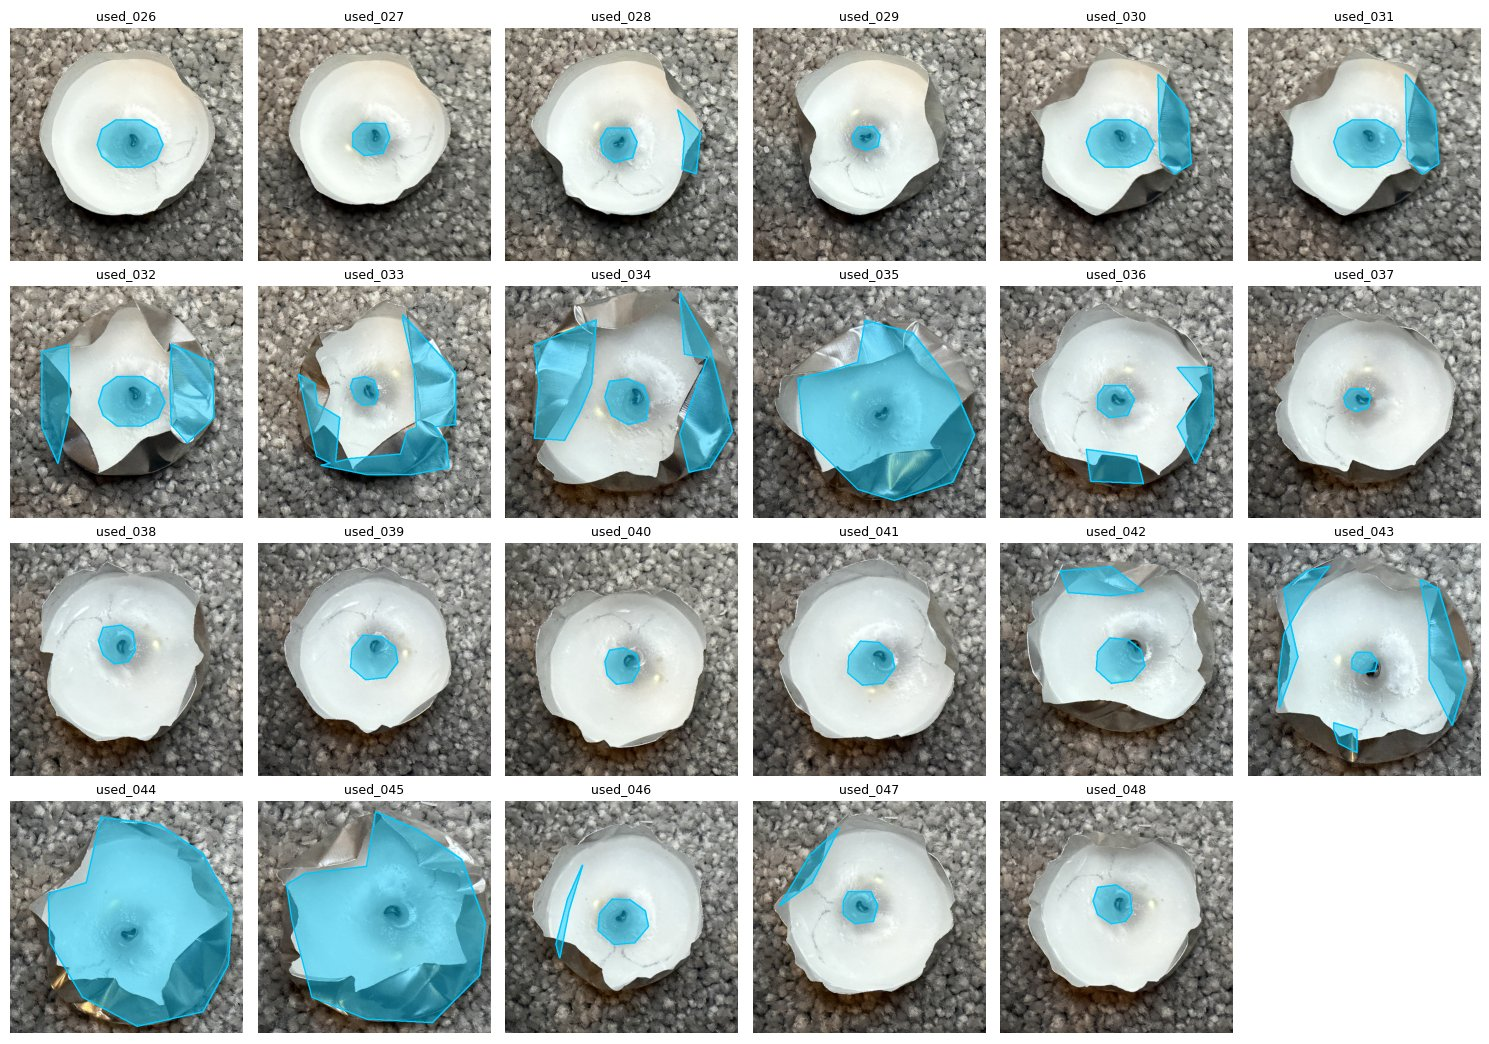

In [9]:
def poly_mask(js, size=512):
    try:
        polys = json.loads(js).get("polygons", [])
    except (json.JSONDecodeError, AttributeError):
        polys = []
    m = Image.new("L", (size, size), 0); dr = ImageDraw.Draw(m)
    for p in polys:
        if len(p) >= 3:
            dr.polygon([tuple(map(float, pt)) for pt in p], fill=255)
    return np.array(m) > 0

id2name = dict(zip(key.id, key.name))
ai = {id2name[i]: poly_mask(js) for i, js in answers.items() if i in id2name}
print("answers that couldn't be read (no polygons):", [n for n, m in ai.items() if not m.any()])
os.makedirs(f"{ANN}/gemini_masks", exist_ok=True)
for n, m in ai.items():
    Image.fromarray((m * 255).astype(np.uint8)).save(f"{ANN}/gemini_masks/{n}_mask.png")
overlay_sheets(ai, "gemini_mask_check", colour=(0, 200, 255))   # cyan = Gemini

# Part 3: Agreement between me and Gemini

In [10]:
rows = []
for n in sorted(ai):
    rows.append({"image": n, "type": n.split("_")[0], **compare(human[n], ai[n]),
                 "area_me_pct": 100 * human[n].mean(), "area_gemini_pct": 100 * ai[n].mean()})
agree = pd.DataFrame(rows)
print("mean over all images:", agree[["iou", "dice", "pixel_kappa"]].mean().round(3).to_dict())
print(agree.groupby("type")[["iou", "dice", "pixel_kappa", "area_me_pct", "area_gemini_pct"]].mean().round(3))
print("lowest agreement:", agree.nsmallest(5, "iou")[["image", "iou"]].round(3).values.tolist())
agree.to_csv(f"{ANN}/agreement_me_vs_gemini.csv", index=False)

mean over all images: {'iou': 0.517, 'dice': 0.642, 'pixel_kappa': 0.561}
         iou   dice  pixel_kappa  area_me_pct  area_gemini_pct
type                                                          
empty  0.704  0.815        0.703       39.961           35.680
used   0.341  0.480        0.427       14.792            6.884
lowest agreement: [['used_037', 0.056], ['used_048', 0.066], ['used_029', 0.091], ['used_040', 0.103], ['used_006', 0.108]]


### Figure for the report


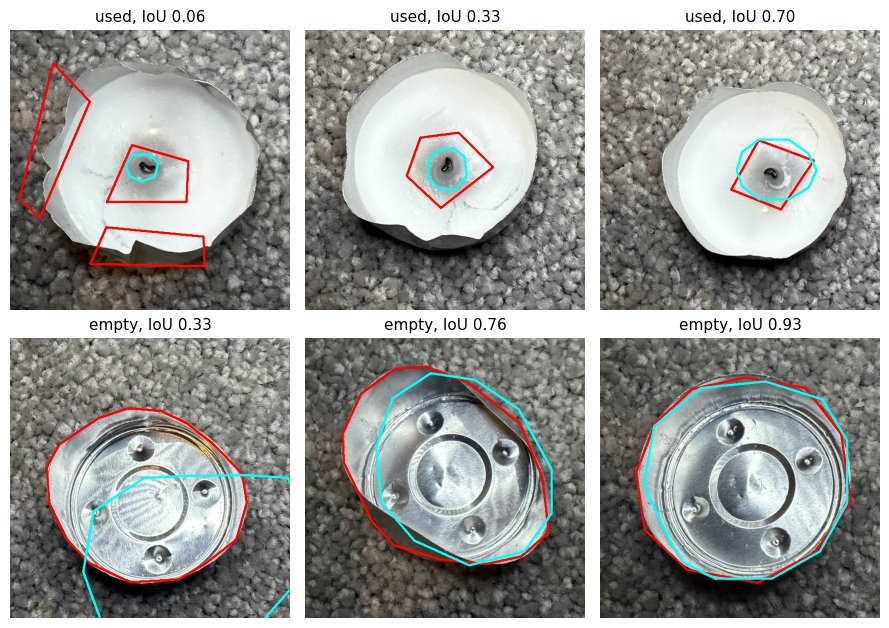

In [11]:
show = []
for t in ["used", "empty"]:
    sub = agree[agree.type == t].sort_values("iou").image.tolist()
    show += [sub[0], sub[len(sub) // 2], sub[-1]]
fig, axes = plt.subplots(2, 3, figsize=(9, 6.4))
for ax, n in zip(axes.flat, show):
    ax.imshow(Image.open(f"{OUT}/test/{n.split('_')[0]}/{n}.png"))
    ax.contour(human[n].astype(float), levels=[0.5], colors="red", linewidths=1.6)
    ax.contour(ai[n].astype(float), levels=[0.5], colors="cyan", linewidths=1.6)
    ax.set_title(f"{n.split('_')[0]}, IoU {agree.set_index('image').loc[n, 'iou']:.2f}", fontsize=11)
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{ANN}/agreement_examples.png", dpi=150); plt.show()